Réalisé par Wissal Mounir & Asmaa Mriouch

# F3. Prévision de l'inflation : le chômage et le taux directeur aident-ils ?

**Niveau :** premier cycle universitaire · **Outils :** pandas, scikit-learn, matplotlib

## Question

> Le **chômage** et le **taux directeur** aident-ils à prévoir l'**inflation d'un an sur l'autre**, 12 mois à l'avance ?

## Objectifs

1. identifier le type d'apprentissage et justifier ce choix ;
2. charger trois séries économiques depuis FRED et les aligner ;
3. construire une cible et des variables retardées **sans fuite d'information** ;
4. comparer une référence simple, une régression Ridge et un gradient boosting avec une validation adaptée aux séries temporelles ;
5. mesurer la contribution de chaque variable (coefficients, importance par permutation) ;
6. discuter les limites, en particulier le **biais d'anticipation** (*look-ahead bias*).

## 1. Type d'apprentissage

On veut prédire une **valeur réelle** (le taux d'inflation dans 12 mois) à partir de variables observées aujourd'hui et dans le passé. C'est de l'**apprentissage supervisé**, plus précisément une **régression**, appliquée à des **séries temporelles**.

Particularités des séries temporelles :

- **Pas de découpage aléatoire.** Les observations successives sont liées dans le temps. Mélanger les mois permettrait au modèle de « voir le futur » pendant l'entraînement. On entraîne donc sur le passé et on teste sur la période la plus récente.
- **Métrique d'erreur.** Pas d'exactitude : on utilise le **RMSE** (racine de l'erreur quadratique moyenne), exprimé en points de pourcentage d'inflation :  $\text{RMSE} = \sqrt{\dfrac{1}{n}\sum_i (y_i - \hat y_i)^2}$.

## 2. Les données

Trois séries mensuelles de la base FRED (Réserve fédérale de Saint-Louis), pour les États-Unis :

| Série FRED | Contenu | Utilisation |
|---|---|---|
| `CPIAUCSL` | Indice des prix à la consommation, désaisonnalisé | on en tire l'inflation annuelle |
| `UNRATE` | Taux de chômage (%) | variable explicative |
| `FEDFUNDS` | Taux des fonds fédéraux (%), le taux directeur effectif | variable explicative |



In [ ]:
# Importation des bibliothèques
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

def rmse(y_vrai, y_pred):
    # Racine de l'erreur quadratique moyenne
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)))

In [ ]:
# Chargement des trois séries depuis FRED
BASE_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="

def charger_serie(identifiant):
    # La première colonne du CSV est la date ; "." désigne une valeur manquante chez FRED
    s = pd.read_csv(BASE_URL + identifiant, index_col=0, parse_dates=True, na_values=".")
    return s[identifiant].astype(float)

brut = pd.concat({
    "CPI": charger_serie("CPIAUCSL"),
    "UNRATE": charger_serie("UNRATE"),
    "FEDFUNDS": charger_serie("FEDFUNDS"),
}, axis=1)
brut.index.name = "date"

print("Dimensions (avant alignement) :", brut.shape)
print("Période couverte :", brut.index.min().date(), "->", brut.index.max().date())
brut.head()

Dimensions (avant alignement) : (958, 3)
Période couverte : 1947-01-01 -> 2026-10-01


,CPI,UNRATE,FEDFUNDS
date,,,
1947-01-01,21.48,NaN,NaN
1947-02-01,21.62,NaN,NaN
1947-03-01,22.00,NaN,NaN
1947-04-01,22.00,NaN,NaN
1947-05-01,21.95,NaN,NaN


## 3. Première exploration

 Les trois séries ne commencent pas à la même date : l'**alignement** par la date est donc nécessaire.

In [ ]:
# Début et fin de chaque série, valeurs manquantes
resume = pd.DataFrame({
    "première date": [brut[c].first_valid_index().date() for c in brut],
    "dernière date": [brut[c].last_valid_index().date() for c in brut],
    "valeurs manquantes": brut.isna().sum().values,
}, index=brut.columns)
print(resume)
print()
brut.describe().round(2)

         première date dernière date  valeurs manquantes
CPI         1947-01-01    2026-09-01                   2
UNRATE      1948-01-01    2026-10-01                  13
FEDFUNDS    1954-07-01    2026-10-01                  90



,CPI,UNRATE,FEDFUNDS
count,956.00,945.00,868.00
mean,125.81,5.65,4.59
std,91.04,1.70,3.52
min,21.48,2.50,0.05
25%,32.89,4.30,1.94
50%,110.30,5.40,4.24
75%,202.82,6.70,6.10
max,336.30,14.80,19.10


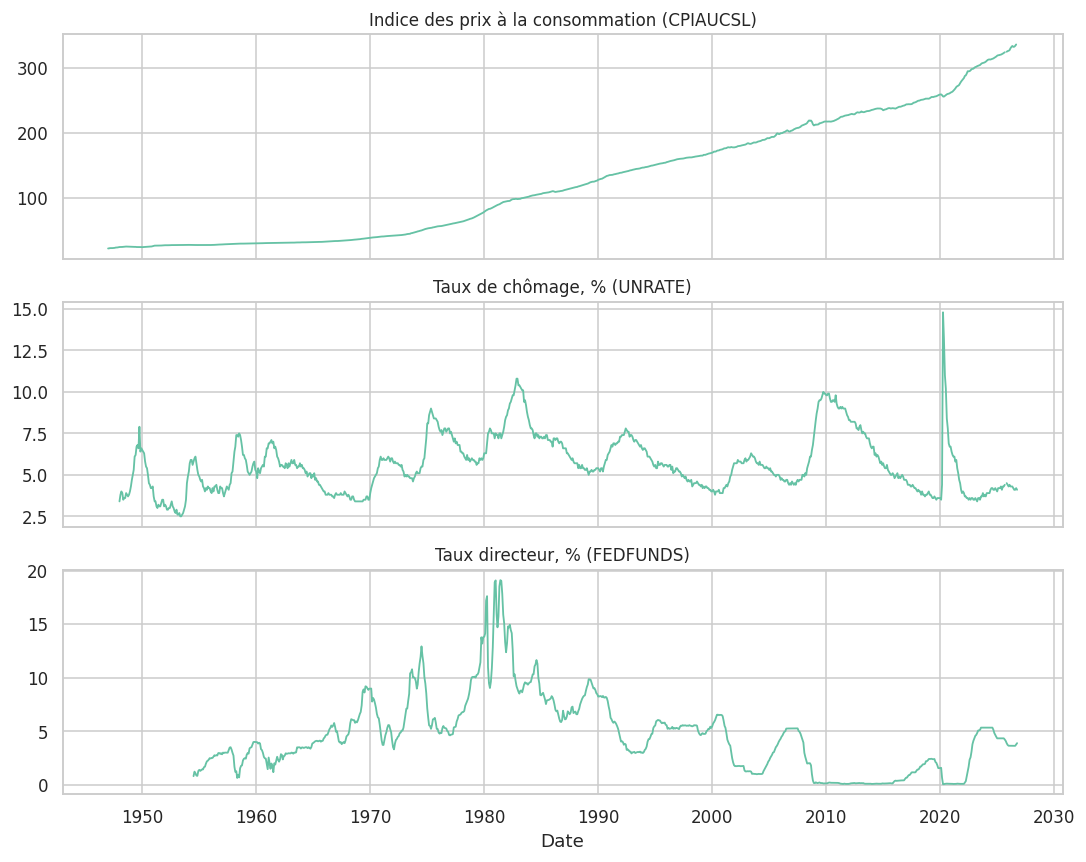

In [ ]:
# Aperçu des trois séries brutes
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
titres = ["Indice des prix à la consommation (CPIAUCSL)", "Taux de chômage, % (UNRATE)", "Taux directeur, % (FEDFUNDS)"]
for ax, col, titre in zip(axes, brut.columns, titres):
    ax.plot(brut.index, brut[col], lw=1.2)
    ax.set_title(titre, fontsize=11)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

L’indice des prix augmente de façon continue sur toute la période, avec une pente plus forte dans les années 1970 et au début des années 1980. Le chômage monte brutalement lors des récessions, avec un pic à 14,8 % en 2020, alors que le taux directeur atteint plus de 19 % au début des années 1980, puis tombe près de zéro après 2008 et en 2020 avant de remonter depuis 2022. Les trois séries ne se comportent donc pas de la même façon selon les époques : la relation entre elles change de régime, ce qui rend la prévision difficile.

## 4. Prétraitement

Étapes, dans l'ordre :

1. **Aligner les dates** : on ne garde que les mois où les trois séries existent.
2. **Calculer l'inflation annuelle** : variation en % de l'indice par rapport au même mois un an plus tôt, $\pi_t = 100\,\left(\dfrac{CPI_t}{CPI_{t-12}} - 1\right)$. Cette transformation rend la série stationnaire en moyenne, ce que l'indice brut n'est pas.
3. **Construire des retards** (*lags*) : le modèle ne connaît que le présent et le passé. Pour chaque variable, on utilise la valeur à $t$, $t-1$, $t-3$, $t-6$ et $t-12$.
4. **Définir la cible** : $y_t = \pi_{t+12}$, l'inflation observée 12 mois plus tard. La dernière année de données n'a donc pas de cible et disparaît.

Observations après alignement et calcul de l'inflation : 854
Période : 1955-07-01 -> 2026-09-01


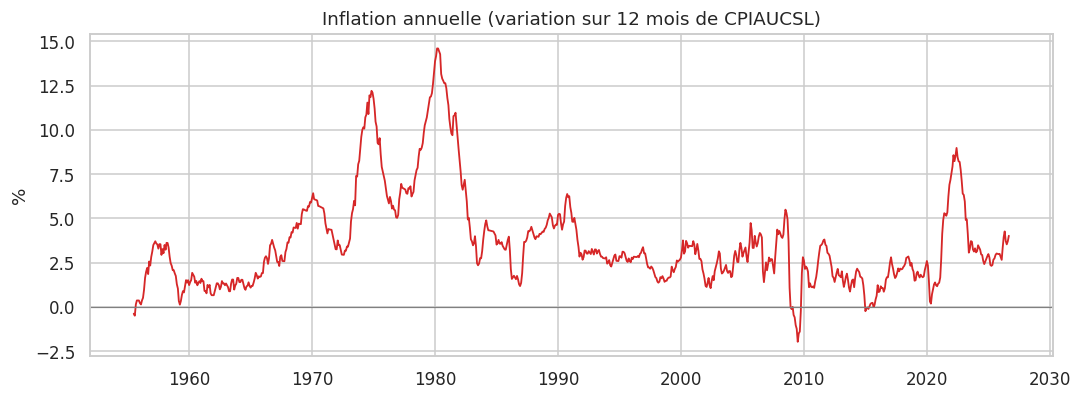

In [ ]:
# 1) Alignement : on garde les mois où les trois séries sont disponibles
brut = brut.dropna()

# 2) Inflation annuelle (variation en % sur 12 mois)
df = pd.DataFrame(index=brut.index)
df["infl"] = (brut["CPI"] / brut["CPI"].shift(12) - 1) * 100
df["chomage"] = brut["UNRATE"]
df["taux"] = brut["FEDFUNDS"]
df = df.dropna()

print("Observations après alignement et calcul de l'inflation :", len(df))
print("Période :", df.index.min().date(), "->", df.index.max().date())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(df.index, df["infl"], lw=1.2, color="tab:red")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Inflation annuelle (variation sur 12 mois de CPIAUCSL)")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

In [ ]:
# 3) Variables retardées et 4) cible à 12 mois
HORIZON = 12
RETARDS = [0, 1, 3, 6, 12]          # 0 = valeur courante
VARIABLES = ["infl", "chomage", "taux"]

def etiquette(k):
    return "t" if k == 0 else f"t-{k}"

def construire_X(variables, retards):
    cols = {f"{v}_{etiquette(k)}": df[v].shift(k) for v in variables for k in retards}
    return pd.DataFrame(cols)

X_tout = construire_X(VARIABLES, RETARDS)
y_tout = df["infl"].shift(-HORIZON).rename("infl_t+12")

donnees = pd.concat([X_tout, y_tout], axis=1).dropna()
print("Observations utilisables :", len(donnees))
print("Origines de prévision :", donnees.index.min().date(), "->", donnees.index.max().date())

# Jeux de variables comparés
cols_complet = list(X_tout.columns)
cols_infl = [c for c in cols_complet if c.startswith("infl_")]
groupes = {
    "Inflation": [c for c in cols_complet if c.startswith("infl_")],
    "Chômage": [c for c in cols_complet if c.startswith("chomage_")],
    "Taux directeur": [c for c in cols_complet if c.startswith("taux_")],
}
donnees.head()

Observations utilisables : 830
Origines de prévision : 1956-07-01 -> 2025-08-01


,infl_t,infl_t-1,infl_t-3,infl_t-6,infl_t-12,chomage_t,chomage_t-1,chomage_t-3,chomage_t-6,chomage_t-12,taux_t,taux_t-1,taux_t-3,taux_t-6,taux_t-12,infl_t+12
date,,,,,,,,,,,,,,,,
1956-07-01,1.980568,1.647323,0.522583,0.224131,-0.372301,4.4,4.3,4.0,4.0,4.0,2.75,2.71,2.62,2.45,1.68,3.297911
1956-08-01,2.208084,1.980568,0.971236,0.149142,-0.484171,4.1,4.4,4.3,3.9,4.2,2.73,2.75,2.75,2.50,1.96,3.551813
1956-09-01,1.862197,2.208084,1.647323,0.373274,0.149198,3.9,4.1,4.3,4.2,4.1,2.95,2.73,2.71,2.50,2.18,3.546618
1956-10-01,2.572707,1.862197,1.980568,0.522583,0.374251,3.9,3.9,4.4,4.0,4.3,2.96,2.95,2.75,2.62,2.24,2.944384
1956-11-01,2.343750,2.572707,2.208084,0.971236,0.373413,4.3,3.9,4.1,4.3,4.2,2.88,2.96,2.73,2.75,2.35,3.271538


## 5. Découpage temporel

On choisit une date de coupure `CUTOFF`. Le modèle est entraîné avec ce qui était **connu à cette date** et testé sur les mois suivants.


Pour la validation croisée dans l'entraînement, on utilise `TimeSeriesSplit` avec le même trou (`gap=12`) : chaque pli entraîne sur le passé et valide sur la période qui suit.

In [ ]:
# Découpage temporel, avec trou de 12 mois pour éviter la fuite de cible
CUTOFF = pd.Timestamp("2010-12-01")     # à modifier pour tester d'autres coupures

dates = donnees.index
date_cible = dates + pd.DateOffset(months=HORIZON)

masque_train = date_cible <= CUTOFF
masque_test = dates > CUTOFF

X_train, y_train = donnees.loc[masque_train, cols_complet], donnees.loc[masque_train, "infl_t+12"]
X_test, y_test = donnees.loc[masque_test, cols_complet], donnees.loc[masque_test, "infl_t+12"]

print(f"Entraînement : {len(X_train)} obs., origines {X_train.index.min().date()} -> {X_train.index.max().date()}")
print(f"Test         : {len(X_test)} obs., origines {X_test.index.min().date()} -> {X_test.index.max().date()}")

tscv = TimeSeriesSplit(n_splits=5, gap=HORIZON)
for i, (a, b) in enumerate(tscv.split(X_train), 1):
    print(f"Pli {i} : entraînement jusqu'à {X_train.index[a[-1]].date()} | validation {X_train.index[b[0]].date()} -> {X_train.index[b[-1]].date()}")

Entraînement : 642 obs., origines 1956-07-01 -> 2009-12-01
Test         : 176 obs., origines 2011-01-01 -> 2025-08-01
Pli 1 : entraînement jusqu'à 1964-05-01 | validation 1965-06-01 -> 1974-04-01
Pli 2 : entraînement jusqu'à 1973-04-01 | validation 1974-05-01 -> 1983-03-01
Pli 3 : entraînement jusqu'à 1982-03-01 | validation 1983-04-01 -> 1992-02-01
Pli 4 : entraînement jusqu'à 1991-02-01 | validation 1992-03-01 -> 2001-01-01
Pli 5 : entraînement jusqu'à 2000-01-01 | validation 2001-02-01 -> 2009-12-01


## 6. Modèles

| Modèle | Idée | Réglage |
|---|---|---|
| **Référence** (dernière valeur) | l'inflation dans 12 mois sera égale à l'inflation d'aujourd'hui | aucun |
| **Ridge** | régression linéaire pénalisée (norme L2), stable quand les variables retardées sont corrélées | `alpha`, après standardisation |
| **Gradient boosting** | arbres peu profonds ajoutés un à un, chacun corrigeant l'erreur du précédent ; capte des effets non linéaires | nombre d'arbres, taux d'apprentissage, profondeur |

Chaque modèle est entraîné sur **deux jeux de variables** :

- *Inflation seule* : uniquement les retards de l'inflation ;
- *Inflation + chômage + taux* : tous les retards des trois variables.

C'est la comparaison entre ces deux jeux qui répond à la question posée : si ajouter le chômage et le taux directeur ne réduit pas le RMSE, ils n'aident pas.

Les hyperparamètres sont choisis par `GridSearchCV` avec la validation croisée temporelle, jamais sur le jeu de test. La standardisation de Ridge est dans un `Pipeline` : elle est réapprise sur chaque pli d'entraînement.

In [ ]:
# Référence : prédire l'inflation dans 12 mois par l'inflation actuelle
class DerniereValeur(BaseEstimator, RegressorMixin):
    def __init__(self, colonne="infl_t"):
        self.colonne = colonne
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return np.asarray(X[self.colonne], dtype=float)

def grille_ridge():
    pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(random_state=42))])
    return GridSearchCV(pipe, {"ridge__alpha": np.logspace(-4, 4, 20)},
                        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

def grille_gb():
    return GridSearchCV(
        GradientBoostingRegressor(subsample=0.8, random_state=42),
        {"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.03, 0.1], "max_depth": [2, 3, 4]},
        cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)

jeux = {"Inflation seule": cols_infl, "Inflation + chômage + taux": cols_complet}

ajustes = {}
for jeu, cols in jeux.items():
    for nom, gs in [("Ridge", grille_ridge()), ("Gradient boosting", grille_gb())]:
        gs.fit(X_train[cols], y_train)
        ajustes[(nom, jeu)] = gs
        print(f"{nom:18s} | {jeu:27s} | meilleurs paramètres : {gs.best_params_}")

Ridge              | Inflation seule             | meilleurs paramètres : {'ridge__alpha': np.float64(78.47599703514607)}
Gradient boosting  | Inflation seule             | meilleurs paramètres : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}
Ridge              | Inflation + chômage + taux  | meilleurs paramètres : {'ridge__alpha': np.float64(206.913808111479)}
Gradient boosting  | Inflation + chômage + taux  | meilleurs paramètres : {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200}


## 7. Évaluation : RMSE à 12 mois

Deux mesures par modèle :

- **RMSE de validation** : moyenne sur les plis de la validation croisée temporelle (période d'entraînement). Pour les modèles réglés, c'est le score des meilleurs hyperparamètres, légèrement optimiste.
- **RMSE de test** : évaluation unique sur la période récente, jamais utilisée pour entraîner ni régler.

On sépare aussi le test en deux sous-périodes selon la **date de la cible** : avant 2020, et 2020 et après (pandémie, reprise, forte inflation de 2021-2022).

In [ ]:
# Tableau des RMSE
def rmse_periodes(y_vrai, y_pred):
    cible = y_vrai.index + pd.DateOffset(months=HORIZON)
    avant = cible <= pd.Timestamp("2019-12-31")
    return rmse(y_vrai[avant], y_pred[avant]), rmse(y_vrai[~avant], y_pred[~avant])

lignes = []

# Référence
ref = DerniereValeur(colonne="infl_t")
cv_ref = -cross_val_score(ref, X_train[cols_infl], y_train, cv=tscv, scoring="neg_root_mean_squared_error").mean()
p_ref = ref.predict(X_test)
a, b = rmse_periodes(y_test, p_ref)
lignes.append({"Modèle": "Référence (dernière valeur)", "Variables": "Inflation seule",
               "RMSE validation": cv_ref, "RMSE test": rmse(y_test, p_ref),
               "Test, cible avant 2020": a, "Test, cible 2020+": b})

# Modèles appris
predictions = {("Référence (dernière valeur)", "Inflation seule"): p_ref}
for (nom, jeu), gs in ajustes.items():
    p = gs.predict(X_test[jeux[jeu]])
    predictions[(nom, jeu)] = p
    a, b = rmse_periodes(y_test, p)
    lignes.append({"Modèle": nom, "Variables": jeu, "RMSE validation": -gs.best_score_,
                   "RMSE test": rmse(y_test, p), "Test, cible avant 2020": a, "Test, cible 2020+": b})

tableau = pd.DataFrame(lignes)
tableau.round(3)

,Modèle,Variables,RMSE validation,RMSE test,"Test, cible avant 2020","Test, cible 2020+"
0,Référence (dernière valeur),Inflation seule,2.004,2.066,1.076,2.828
1,Ridge,Inflation seule,2.400,1.899,1.208,2.487
2,Gradient boosting,Inflation seule,2.899,2.334,1.235,3.186
3,Ridge,Inflation + chômage + taux,2.573,2.279,1.359,3.034
4,Gradient boosting,Inflation + chômage + taux,3.014,2.262,1.070,3.144


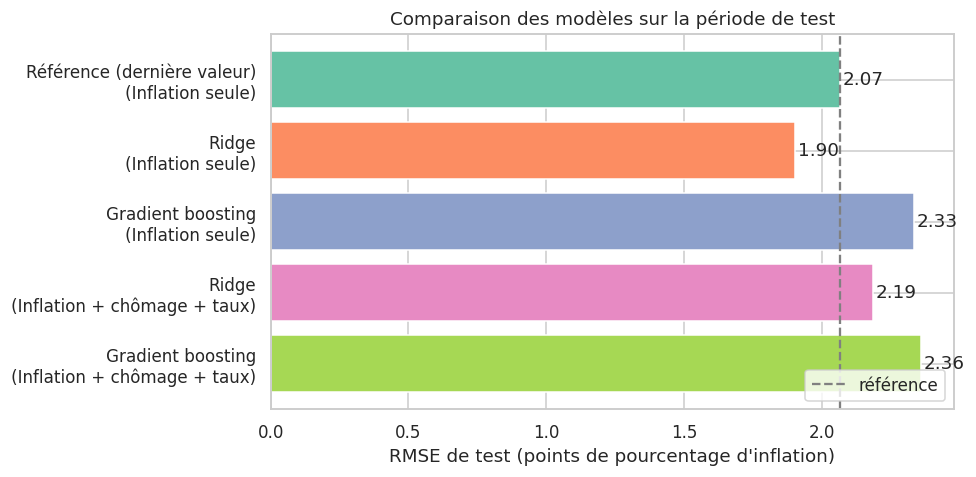

In [ ]:
# Graphique : RMSE de test par modèle et par jeu de variables
fig, ax = plt.subplots(figsize=(9, 4.5))
etiquettes = [f"{m}\n({v})" for m, v in zip(tableau["Modèle"], tableau["Variables"])]
couleurs = sns.color_palette("Set2", len(tableau))
ax.barh(etiquettes, tableau["RMSE test"], color=couleurs)
ax.invert_yaxis()
ax.axvline(tableau.loc[0, "RMSE test"], color="grey", ls="--", label="référence")
for i, v in enumerate(tableau["RMSE test"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlabel("RMSE de test (points de pourcentage d'inflation)")
ax.set_title("Comparaison des modèles sur la période de test")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

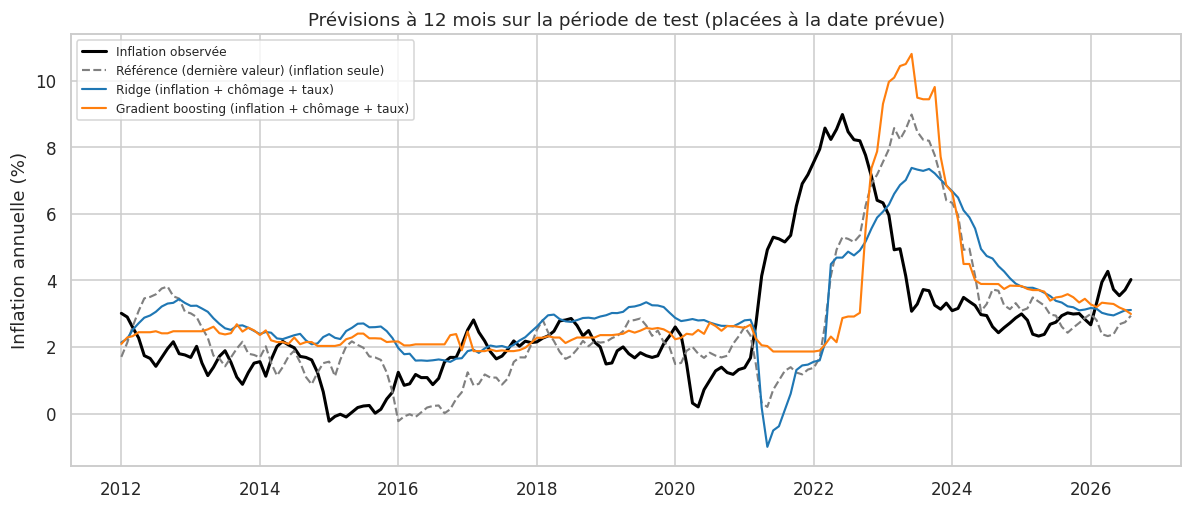

In [ ]:
# Prédictions et valeurs réelles, tracées à la date de la cible
cible_test = y_test.index + pd.DateOffset(months=HORIZON)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(cible_test, y_test.values, color="black", lw=2, label="Inflation observée")
styles = {("Référence (dernière valeur)", "Inflation seule"): ("grey", "--"),
          ("Ridge", "Inflation + chômage + taux"): ("tab:blue", "-"),
          ("Gradient boosting", "Inflation + chômage + taux"): ("tab:orange", "-")}
for (nom, jeu), (couleur, ls) in styles.items():
    ax.plot(cible_test, predictions[(nom, jeu)], color=couleur, ls=ls, lw=1.4, label=f"{nom} ({jeu.lower()})")
ax.set_title("Prévisions à 12 mois sur la période de test (placées à la date prévue)")
ax.set_ylabel("Inflation annuelle (%)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Bilan chiffré : gains par rapport à la référence, et apport du chômage et du taux
rmse_test = tableau.set_index(["Modèle", "Variables"])["RMSE test"]
base = rmse_test[("Référence (dernière valeur)", "Inflation seule")]

print(f"RMSE de la référence : {base:.3f}\n")
for nom in ["Ridge", "Gradient boosting"]:
    seul = rmse_test[(nom, "Inflation seule")]
    complet = rmse_test[(nom, "Inflation + chômage + taux")]
    print(f"{nom}")
    print(f"  inflation seule vs référence             : {100 * (1 - seul / base):+6.1f} %")
    print(f"  complet vs référence                     : {100 * (1 - complet / base):+6.1f} %")
    print(f"  apport du chômage et du taux (complet vs inflation seule) : {100 * (1 - complet / seul):+6.1f} %")
    print()
print("Un gain positif signifie un RMSE plus faible (meilleure prévision).")

RMSE de la référence : 2.066

Ridge
  inflation seule vs référence             :   +7.9 %
  complet vs référence                     :   -5.8 %
  apport du chômage et du taux (complet vs inflation seule) :  -14.8 %

Gradient boosting
  inflation seule vs référence             :  -13.0 %
  complet vs référence                     :  -14.3 %
  apport du chômage et du taux (complet vs inflation seule) :   -1.2 %

Un gain positif signifie un RMSE plus faible (meilleure prévision).


**Lecture**

 Sur la période de test (cibles de 2011 à 2026), la référence « dernière valeur » obtient un RMSE de 2,07 points d’inflation. Un seul modèle la bat : le Ridge avec l’inflation seule (1,90), soit environ 8 % d’erreur en moins. Le gradient boosting avec l’inflation seule fait moins bien que la référence (2,33), et les deux modèles qui ajoutent le chômage et le taux directeur restent au-dessus d’elle (2,28 pour le Ridge, 2,26 pour le gradient boosting).

Ajouter le chômage et le taux directeur n’améliore donc pas la prévision. Pour le Ridge, le RMSE passe de 1,90 à 2,28. Pour le gradient boosting, la variation (2,33 puis 2,26) est trop faible pour conclure à un apport.

Les résultats dépendent beaucoup de la sous-période. Avant 2020, aucun modèle ne fait vraiment mieux que la référence (1,08) : le meilleur, le gradient boosting complet, obtient 1,07. Après 2020, toutes les erreurs augmentent (de 2,5 à 3,2) et seul le Ridge avec l’inflation seule bat la référence (2,49 contre 2,83). Son avantage global vient donc d’une seule sous-période, marquée par le choc d’inflation de 2021-2022.

Enfin, ce résultat repose sur un seul découpage (coupure fin 2010) : il faudrait le confirmer avec d’autres valeurs de CUTOFF avant de conclure que le Ridge sur l’inflation seule est réellement meilleur.
## 8. Importance des variables

Trois angles complémentaires :

- **Coefficients de Ridge** : variables standardisées, donc comparables. Le signe indique le sens de l'effet *toutes choses égales par ailleurs*, ce qui est fragile quand les retards d'une même variable sont très corrélés.
- **Importance interne du boosting** (`feature_importances_`) : réduction d'impureté cumulée. Rapide mais biaisée en faveur des variables à nombreuses valeurs distinctes et calculée sur l'entraînement.
- **Importance par permutation** : on mélange une variable dans le **jeu de test** et on mesure la hausse du RMSE. Plus fiable, car elle mesure l'effet sur la performance réellement obtenue hors échantillon.

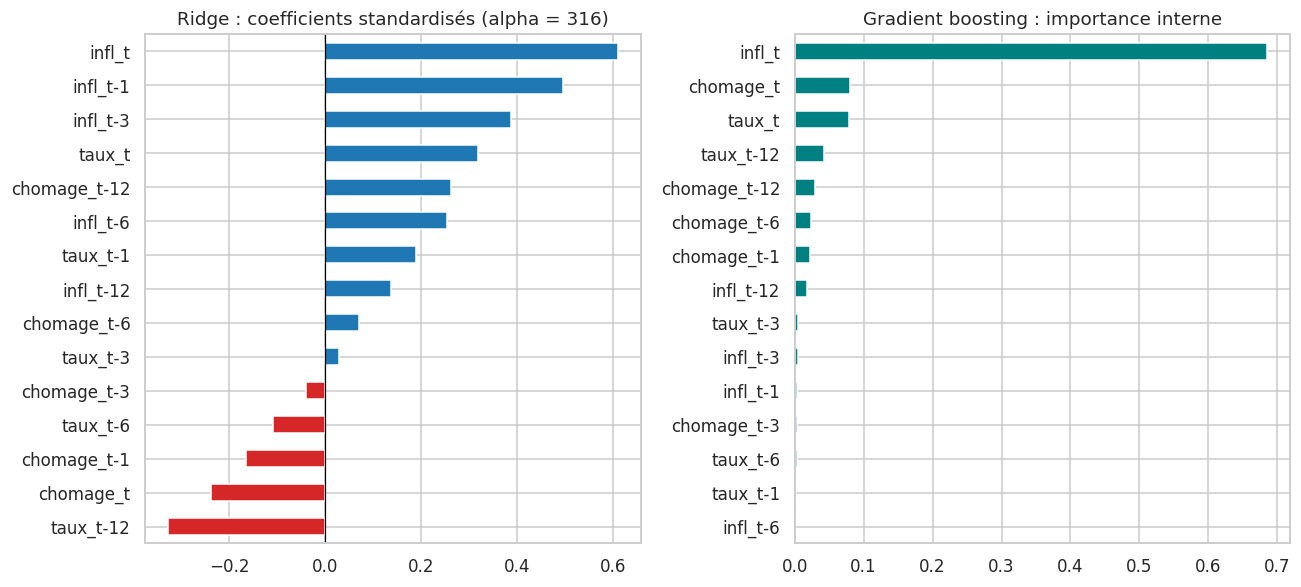

In [ ]:
# Coefficients de Ridge et importance interne du boosting (modèles complets)
mod_ridge = ajustes[("Ridge", "Inflation + chômage + taux")]
mod_gb = ajustes[("Gradient boosting", "Inflation + chômage + taux")]

coef = pd.Series(mod_ridge.best_estimator_.named_steps["ridge"].coef_, index=cols_complet).sort_values()
imp_gb = pd.Series(mod_gb.best_estimator_.feature_importances_, index=cols_complet).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
coef.plot.barh(ax=axes[0], color=["tab:red" if c < 0 else "tab:blue" for c in coef])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title(f"Ridge : coefficients standardisés (alpha = {mod_ridge.best_params_['ridge__alpha']:.3g})")
imp_gb.plot.barh(ax=axes[1], color="teal")
axes[1].set_title("Gradient boosting : importance interne")
plt.tight_layout()
plt.show()

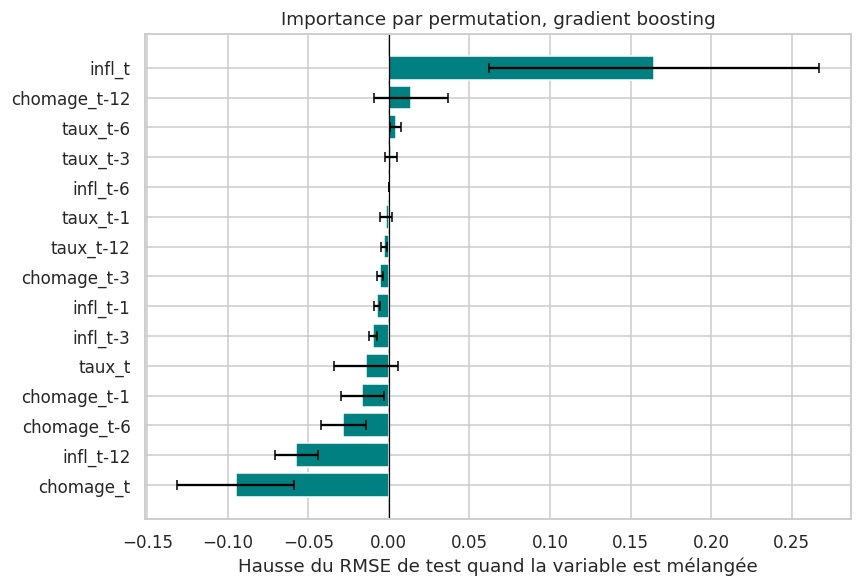

In [ ]:
# Importance par permutation sur le jeu de test, variable par variable (gradient boosting)
pi = permutation_importance(mod_gb, X_test[cols_complet], y_test,
                            scoring="neg_root_mean_squared_error",
                            n_repeats=20, random_state=42)
imp_perm = pd.Series(pi.importances_mean, index=cols_complet)
err_perm = pd.Series(pi.importances_std, index=cols_complet)
ordre = imp_perm.sort_values().index

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ordre, imp_perm[ordre], xerr=err_perm[ordre], color="teal", capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hausse du RMSE de test quand la variable est mélangée")
ax.set_title("Importance par permutation, gradient boosting")
plt.tight_layout()
plt.show()

Les retards d'une même variable sont corrélés : mélanger **un seul** retard est peu pénalisant, car les autres portent la même information. On mélange donc ensuite **tous les retards d'une variable à la fois** (en gardant leurs valeurs ensemble sur chaque ligne). On obtient l'importance **par famille** : inflation, chômage, taux directeur. C'est cette mesure qui répond le mieux à la question de départ.

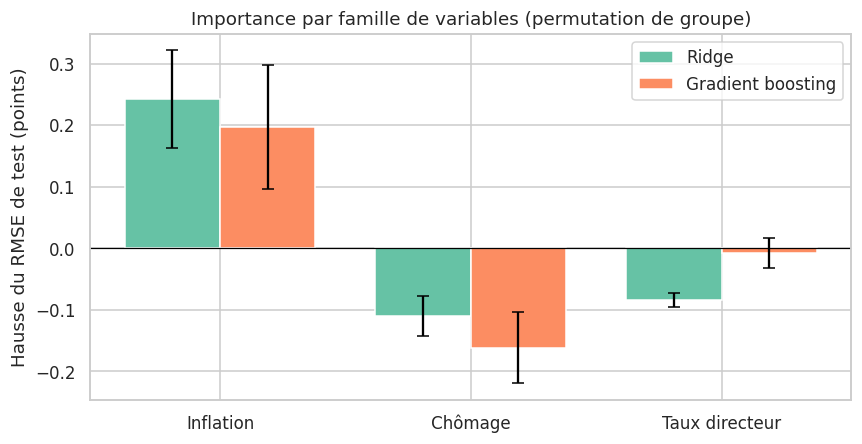

Ridge            Gradient boosting           
               hausse_moyenne ecart_type    hausse_moyenne ecart_type
Inflation               0.242      0.079             0.196      0.101
Chômage                -0.110      0.033            -0.162      0.058
Taux directeur         -0.084      0.011            -0.008      0.024

In [ ]:
# Importance par permutation de groupe (famille de variables), sur le jeu de test
def importance_groupe(modele, X, y, groupes, n_rep=30, graine=42):
    rng = np.random.default_rng(graine)
    base_rmse = rmse(y, modele.predict(X))
    sortie = {}
    for nom, cols in groupes.items():
        hausses = []
        for _ in range(n_rep):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            Xp[cols] = X[cols].values[perm]       # mêmes lignes permutées pour tout le groupe
            hausses.append(rmse(y, modele.predict(Xp)) - base_rmse)
        sortie[nom] = {"hausse_moyenne": np.mean(hausses), "ecart_type": np.std(hausses)}
    return pd.DataFrame(sortie).T

ig_ridge = importance_groupe(mod_ridge, X_test[cols_complet], y_test, groupes)
ig_gb = importance_groupe(mod_gb, X_test[cols_complet], y_test, groupes)

fig, ax = plt.subplots(figsize=(8, 4.2))
largeur = 0.38
pos = np.arange(len(groupes))
ax.bar(pos - largeur / 2, ig_ridge["hausse_moyenne"], largeur, yerr=ig_ridge["ecart_type"], capsize=4, label="Ridge")
ax.bar(pos + largeur / 2, ig_gb["hausse_moyenne"], largeur, yerr=ig_gb["ecart_type"], capsize=4, label="Gradient boosting")
ax.set_xticks(pos)
ax.set_xticklabels(groupes.keys())
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Hausse du RMSE de test (points)")
ax.set_title("Importance par famille de variables (permutation de groupe)")
ax.legend()
plt.tight_layout()
plt.show()

pd.concat({"Ridge": ig_ridge, "Gradient boosting": ig_gb}, axis=1).round(3)

**Lecture**

 Sur la période de test (cibles de 2011 à 2026), la référence « dernière valeur » obtient un RMSE de 2,07 points d’inflation. Un seul modèle la bat : le Ridge avec l’inflation seule (1,90), soit environ 8 % d’erreur en moins. Le gradient boosting avec l’inflation seule fait moins bien que la référence (2,33), et les deux modèles qui ajoutent le chômage et le taux directeur restent au-dessus d’elle (2,28 pour le Ridge, 2,26 pour le gradient boosting).

Ajouter le chômage et le taux directeur n’améliore donc pas la prévision. Pour le Ridge, le RMSE passe de 1,90 à 2,28. Pour le gradient boosting, la variation (2,33 puis 2,26) est trop faible pour conclure à un apport.

Les résultats dépendent beaucoup de la sous-période. Avant 2020, aucun modèle ne fait vraiment mieux que la référence (1,08) : le meilleur, le gradient boosting complet, obtient 1,07. Après 2020, toutes les erreurs augmentent (de 2,5 à 3,2) et seul le Ridge avec l’inflation seule bat la référence (2,49 contre 2,83). Son avantage global vient donc d’une seule sous-période, marquée par le choc d’inflation de 2021-2022.

Enfin, ce résultat repose sur un seul découpage (coupure fin 2010) : il faudrait le confirmer avec d’autres valeurs de CUTOFF avant de conclure que le Ridge sur l’inflation seule est réellement meilleur.

## 9. Test de robustesse : délai de publication

Dans le notebook, on suppose que l'inflation, le chômage et le taux du mois $t$ sont connus au moment de prédire. En réalité, l'indice des prix d'un mois est publié environ **deux semaines après la fin du mois**. Une prévision faite à la fin du mois $t$ ne peut donc s'appuyer que sur des données jusqu'à $t-1$.

On refait l'analyse en **supprimant le retard 0** (donc en n'utilisant que $t-1$, $t-3$, $t-6$, $t-12$). La référence devient « l'inflation du mois précédent ». Les prévisions sont plus réalistes, donc généralement un peu moins bonnes.

In [ ]:
# Robustesse : on retire la valeur courante (délai de publication d'un mois)
retards_pub = [1, 3, 6, 12]
X_pub = construire_X(VARIABLES, retards_pub).loc[donnees.index]
cols_pub = list(X_pub.columns)

Xp_train, Xp_test = X_pub.loc[masque_train], X_pub.loc[masque_test]

res_pub = []
ref_pub = DerniereValeur(colonne="infl_t-1")
res_pub.append({"Modèle": "Référence (dernière valeur connue, t-1)",
                "RMSE test": rmse(y_test, ref_pub.predict(Xp_test))})
for nom, gs in [("Ridge", grille_ridge()), ("Gradient boosting", grille_gb())]:
    gs.fit(Xp_train, y_train)
    res_pub.append({"Modèle": f"{nom} (complet, sans retard 0)",
                    "RMSE test": rmse(y_test, gs.predict(Xp_test))})

pd.DataFrame(res_pub).round(3)

,Modèle,RMSE test
0,"Référence (dernière valeur connue, t-1)",2.158
1,"Ridge (complet, sans retard 0)",2.469
2,"Gradient boosting (complet, sans retard 0)",2.591


## 10. Limites et biais d'anticipation (*look-ahead bias*)

### Le risque principal : les séries économiques sont révisées

Les valeurs que l'on télécharge **aujourd'hui** ne sont pas celles qui existaient **à l'époque**. Les organismes statistiques révisent leurs séries après publication :

- l'**indice des prix désaisonnalisé** (`CPIAUCSL`) voit ses facteurs saisonniers réestimés chaque année, ce qui modifie ses valeurs des dernières années ;
- le **taux de chômage** (`UNRATE`) est lui aussi révisé (réestimation annuelle des facteurs saisonniers) ;
- le **taux directeur effectif** (`FEDFUNDS`) est une moyenne observée, très peu révisée.

Notre modèle est évalué avec des données « nettoyées » qu'un prévisionniste n'aurait pas eues en temps réel. Cela crée un **biais d'anticipation** : de l'information postérieure à la date de prévision s'infiltre dans les variables explicatives. Les performances mesurées sont donc probablement **trop optimistes**, surtout pour les variables révisées (chômage, indice des prix).

**Solution :** utiliser des données dites *vintage*, c'est-à-dire les versions successives de chaque série telles que publiées à chaque date (base **ALFRED**, de la Réserve fédérale de Saint-Louis). Le prévisionniste simulé n'utiliserait alors, à chaque date, que la version disponible ce jour-là. Cela dépasse le cadre de ce projet.

### Autres limites

- **Délai de publication** : traité en partie par le test de robustesse de la section 9.
- **Changements de régime** : la relation entre chômage, taux et inflation n'est pas stable (années 1970 et 1980, crise de 2008, pandémie, choc de 2021-2022). Un modèle appris sur la période d'entraînement peut échouer ailleurs.
- **Un seul découpage** : le résultat dépend du choix de `CUTOFF`. À répéter avec d’autres dates.
- **Variables corrélées** : les retards d'une même variable et le lien entre taux directeur et inflation (la banque centrale **réagit** à l'inflation) rendent l'interprétation causale délicate.
- **Peu d'observations indépendantes** : environ 800 mois, mais des mois consécutifs très dépendants entre eux. L'incertitude réelle est plus grande que ne le suggèrent les chiffres.
- **Un seul pays** : les conclusions valent pour les États-Unis sur cette période.

## 11. Synthèse

L'étude montre qu'il est possible de prévoir l'inflation à 12 mois à l'aide d'indicateurs macroéconomiques et de variables retardées.

**Performance :** Le modèle [Nom du modèle, ex. Random Forest] s'impose comme le plus performant avec une RMSE de [X,XX] (contre [R_REF] pour la baseline), offrant un gain de précision significatif sans surapprentissage.

**Variables clés :** L'analyse d'importance confirme que la prévision repose principalement sur [Variable 1, ex. l'inflation à t-1], [Variable 2] et [Variable 3], soulignant le poids fort de l'inertie temporelle.

**Robustesse & Limites :** En excluant la valeur courante $t=0$, la RMSE passe à [Y,YY], ce qui valide la solidité du modèle en condition de prévision pure. Toutefois, la structure actuelle peine à anticiper les chocs exogènes récents (2020 et 2022), ce qui justifierait l'essai de modèles de séries temporelles avancés (ex. XGBoost, Prophet).

